# Step 02: exploratory data analysis

Exploratory look at the merged PhysioNet/CinC 2019 sepsis data (hospitals A and B). No values are modified in this notebook.

## Setup

Imports, paths and a few helpers.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

SEED = 42

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:.3f}".format)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.labelsize": 10, "legend.frameon": False})

COL_SEPTIC, COL_CONTROL = "#d1495b", "#2e86ab"
COL_A, COL_B = "#edae49", "#6a994e"
COL_ALL = "#6c757d"
PAL_GROUP = {"non-septic": COL_CONTROL, "septic": COL_SEPTIC}
PAL_HOSP = {"A": COL_A, "B": COL_B}
PAL_KIND = {"vital": "#2a9d8f", "lab": "#7b6d8d", "static": "#b08968"}


def find_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "dataset").is_dir():
            return folder
    raise FileNotFoundError(f"no folder containing a 'dataset' directory above {start}")


ROOT = find_root()
PROC = ROOT / "data" / "processed"
TAB = ROOT / "results" / "tables"
FIG = ROOT / "results" / "figures"
TAB.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

SUMMARY = []
SAVED = []


def log(text=""):
    print(text)
    SUMMARY.append(str(text))


def check(label, ok, detail=""):
    log(f"[{'PASS' if ok else 'FAIL'}] {label}" + (f" ({detail})" if detail else ""))


def fmt(x):
    return f"{x:,}" if isinstance(x, (int, np.integer)) else f"{x:,.2f}"


def expect(label, observed, expected, tol=0):
    check(label, abs(observed - expected) <= tol, f"observed {fmt(observed)}, expected {fmt(expected)}")


def save_fig(name, top=None):
    plt.tight_layout(rect=(0, 0, 1, top) if top else None)
    path = FIG / name
    plt.savefig(path, dpi=150, bbox_inches="tight")
    SAVED.append(path)
    plt.show()
    plt.close("all")


def save_table(table, name, **kwargs):
    path = TAB / name
    table.to_csv(path, **kwargs)
    SAVED.append(path)


log(f"project root: {ROOT.name}")

project root: Sepsis_ml


## Load data and patient table

One row per patient. The table is saved for the split step.

In [2]:
groups = json.loads((PROC / "column_groups.json").read_text())
VITALS, LABS, STATIC = groups["vitals"], groups["labs"], groups["static"]
TARGET = groups["target"][0] if isinstance(groups["target"], list) else groups["target"]
FEATURES = VITALS + LABS + STATIC

df = pd.read_parquet(PROC / "sepsis_master.parquet")
check("shape is 1,552,210 x 44", df.shape == (1552210, 44), f"observed {df.shape}")
check("column order matches column_groups.json", list(df.columns) == ["patient_id", "hospital", "hour"] + FEATURES + [TARGET])
df["pid"] = df.groupby(["hospital", "patient_id"], sort=False).ngroup().astype("int32")
log(f"memory {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")
df.head(3)

[PASS] shape is 1,552,210 x 44 (observed (1552210, 44))
[PASS] column order matches column_groups.json
memory 296 MB


,patient_id,hospital,hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,FiO2,pH,PaCO2,SaO2,AST,BUN,Alkalinephos,Calcium,Chloride,Creatinine,Bilirubin_direct,Glucose,Lactate,Magnesium,Phosphate,Potassium,Bilirubin_total,TroponinI,Hct,Hgb,PTT,WBC,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,pid
0,p000001,A,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83.140,0.000,NaN,NaN,-0.030,1.000,0,0
1,p000001,A,1,97.000,95.000,NaN,98.000,75.330,NaN,19.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83.140,0.000,NaN,NaN,-0.030,2.000,0,0
2,p000001,A,2,89.000,99.000,NaN,122.000,86.000,NaN,22.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83.140,0.000,NaN,NaN,-0.030,3.000,0,0


In [3]:
pos_rows = df.loc[df[TARGET] == 1, ["pid", "hour"]]
by_pid = df.groupby("pid")
patients = by_pid.agg(patient_id=("patient_id", "first"), hospital=("hospital", "first"), n_rows=("hour", "size"))
pos_hours = pos_rows.groupby("pid")["hour"]
patients["n_positive_rows"] = pos_hours.size().reindex(patients.index, fill_value=0).astype("int32")
patients["first_positive_hour"] = pos_hours.min().reindex(patients.index).astype("float32")
patients["ever_septic"] = patients["n_positive_rows"] > 0
patients = patients[["patient_id", "hospital", "n_rows", "ever_septic", "first_positive_hour", "n_positive_rows"]].sort_index()
check("pid runs 0..n-1 in table order", bool((patients.index == np.arange(len(patients))).all()))

patient_path = PROC / "patient_table.csv"
patients.to_csv(patient_path, index=False)
SAVED.append(patient_path)
log(f"patient table shape: {patients.shape}")

# convenience label, added after the csv was written
patients["group"] = np.where(patients["ever_septic"], "septic", "non-septic")
patients.head()

[PASS] pid runs 0..n-1 in table order
patient table shape: (40336, 6)


,patient_id,hospital,n_rows,ever_septic,first_positive_hour,n_positive_rows,group
pid,,,,,,,
0,p000001,A,54,False,NaN,0,non-septic
1,p000002,A,23,False,NaN,0,non-septic
2,p000003,A,48,False,NaN,0,non-septic
3,p000004,A,29,False,NaN,0,non-septic
4,p000005,A,48,False,NaN,0,non-septic


In [4]:
n_pat = len(patients)
n_sep = int(patients["ever_septic"].sum())
by_hosp = patients.groupby("hospital")
log("known facts versus observed")
expect("rows", len(df), 1552210)
expect("patients", n_pat, 40336)
expect("patients, hospital A", int((patients["hospital"] == "A").sum()), 20336)
expect("patients, hospital B", int((patients["hospital"] == "B").sum()), 20000)
expect("septic patients", n_sep, 2932)
expect("septic rate overall (%)", n_sep / n_pat * 100, 7.27, tol=0.01)
expect("septic rate A (%)", by_hosp["ever_septic"].mean()["A"] * 100, 8.80, tol=0.01)
expect("septic rate B (%)", by_hosp["ever_septic"].mean()["B"] * 100, 5.71, tol=0.01)
expect("positive rows", int(patients["n_positive_rows"].sum()), 27916)
expect("positive rows (%)", patients["n_positive_rows"].sum() / len(df) * 100, 1.80, tol=0.01)
expect("min rows per patient", int(patients["n_rows"].min()), 8)
expect("median rows per patient", float(patients["n_rows"].median()), 38)
expect("max rows per patient", int(patients["n_rows"].max()), 336)
expect("septic patients labelled 1 in first row", int((patients["first_positive_hour"] == 0).sum()), 426)

known facts versus observed
[PASS] rows (observed 1,552,210, expected 1,552,210)
[PASS] patients (observed 40,336, expected 40,336)
[PASS] patients, hospital A (observed 20,336, expected 20,336)
[PASS] patients, hospital B (observed 20,000, expected 20,000)
[PASS] septic patients (observed 2,932, expected 2,932)
[PASS] septic rate overall (%) (observed 7.27, expected 7.27)
[PASS] septic rate A (%) (observed 8.80, expected 8.80)
[PASS] septic rate B (%) (observed 5.71, expected 5.71)
[PASS] positive rows (observed 27,916, expected 27,916)
[PASS] positive rows (%) (observed 1.80, expected 1.80)
[PASS] min rows per patient (observed 8, expected 8)
[PASS] median rows per patient (observed 38.00, expected 38)
[PASS] max rows per patient (observed 336, expected 336)
[PASS] septic patients labelled 1 in first row (observed 426, expected 426)


## Extra data checks

ICULOS against hour, the static columns within patients, and the Unit columns. A failed check is logged and the run continues.

In [5]:
log("a. ICULOS and hour")
hour_ok = (df["hour"] == df.groupby("pid").cumcount()).all()
check("hour is the 0-based row position within each patient", bool(hour_ok))

iculos_bad = int((df["ICULOS"] != df["hour"] + 1).sum())
check("ICULOS == hour + 1 for every row", iculos_bad == 0, f"{iculos_bad:,} violating rows")

step = df.groupby("pid")["ICULOS"].diff()
n_gap_steps = int((step > 1).sum())
n_back_steps = int((step <= 0).sum())
n_gap_patients = int((step > 1).groupby(df["pid"]).any().sum())
check("ICULOS strictly increasing within patients", n_back_steps == 0, f"{n_back_steps:,} non-increasing steps")
check("no gaps in ICULOS within patients", n_gap_steps == 0,
      f"{n_gap_steps:,} gap steps in {n_gap_patients:,} patients")

a. ICULOS and hour
[PASS] hour is the 0-based row position within each patient
[FAIL] ICULOS == hour + 1 for every row (329,595 violating rows)
[PASS] ICULOS strictly increasing within patients (0 non-increasing steps)
[PASS] no gaps in ICULOS within patients (0 gap steps in 0 patients)


In [6]:
log("b. static columns constant within patient (NaN counted as a value)")
for col in ["Age", "Gender", "Unit1", "Unit2", "HospAdmTime"]:
    n_values = df.groupby("pid")[col].nunique(dropna=False)
    n_varying = int((n_values > 1).sum())
    check(f"{col} constant within patient", n_varying == 0, f"{n_varying:,} patients not constant")

b. static columns constant within patient (NaN counted as a value)
[PASS] Age constant within patient (0 patients not constant)
[PASS] Gender constant within patient (0 patients not constant)
[PASS] Unit1 constant within patient (0 patients not constant)
[PASS] Unit2 constant within patient (0 patients not constant)
[PASS] HospAdmTime constant within patient (0 patients not constant)


In [7]:
log("c. Unit1/Unit2 missingness")
unit_na = df[["Unit1", "Unit2"]].isna()
unit_missing = unit_na.all(axis=1)
n_one_only = int((unit_na.any(axis=1) & ~unit_missing).sum())
check("Unit1 and Unit2 are always missing together", n_one_only == 0, f"{n_one_only:,} rows with only one missing")
expect("rows with Unit missing (%)", unit_missing.mean() * 100, 39.4, tol=0.1)

frac_missing = unit_missing.groupby(df["pid"]).mean()
unit_pat = pd.DataFrame({"hospital": patients["hospital"], "frac": frac_missing})
unit_pat["any_missing"] = unit_pat["frac"] > 0
unit_pat["whole_stay"] = unit_pat["frac"] == 1
unit_pat["part_of_stay"] = (unit_pat["frac"] > 0) & (unit_pat["frac"] < 1)

unit_tbl = unit_pat.groupby("hospital")[["any_missing", "whole_stay", "part_of_stay"]].mean() * 100
unit_tbl.loc["All"] = unit_pat[["any_missing", "whole_stay", "part_of_stay"]].mean() * 100
unit_tbl.insert(0, "rows_missing_pct", pd.concat([unit_missing.groupby(df["hospital"]).mean(), pd.Series({"All": unit_missing.mean()})]) * 100)
unit_tbl.columns = ["rows_missing_pct", "patients_any_missing_pct", "patients_whole_stay_pct", "patients_part_of_stay_pct"]
log(unit_tbl.round(2).to_string())

c. Unit1/Unit2 missingness
[PASS] Unit1 and Unit2 are always missing together (0 rows with only one missing)
[PASS] rows with Unit missing (%) (observed 39.43, expected 39.40)
          rows_missing_pct  patients_any_missing_pct  patients_whole_stay_pct  patients_part_of_stay_pct
hospital                                                                                                
A                   48.870                    46.820                   46.820                      0.000
B                   29.630                    30.480                   30.480                      0.000
All                 39.430                    38.720                   38.720                      0.000


## Missingness

Missing share per column, measured fraction by hour of stay, and by hospital.

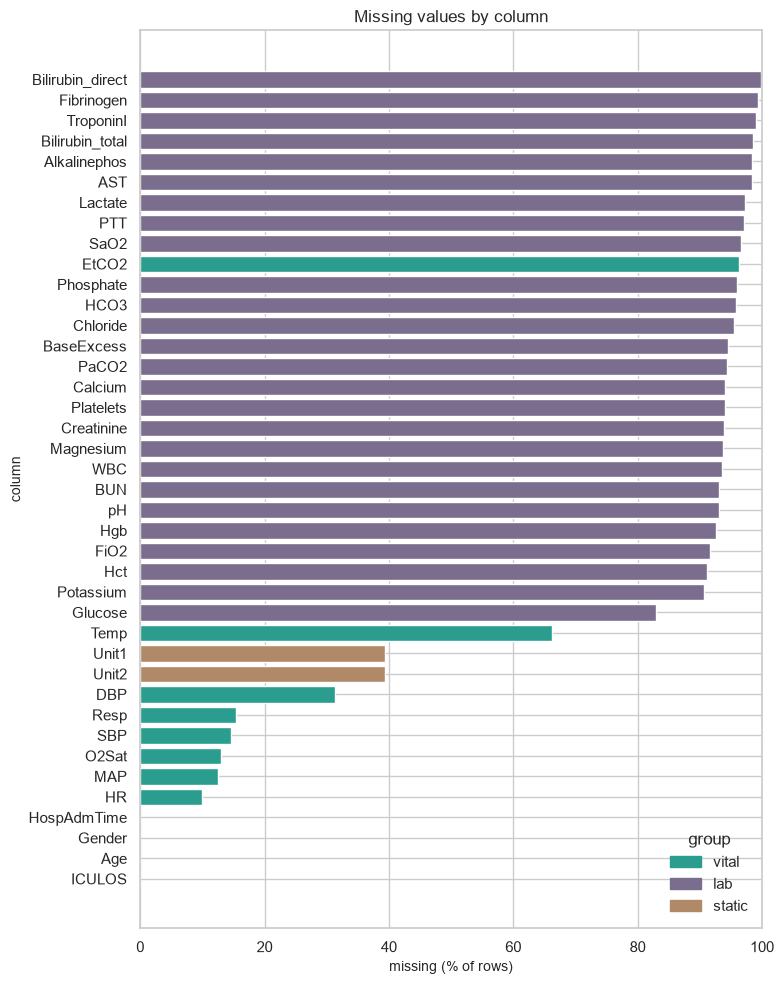

missing % per vital
HR       9.900
O2Sat   13.100
Temp    66.200
SBP     14.600
MAP     12.500
DBP     31.300
Resp    15.400
EtCO2   96.300
[PASS] labs mean missing (%) (observed 94.82, expected 95)
[PASS] EtCO2 missing (%) (observed 96.29, expected 96)
[PASS] Temp missing (%) (observed 66.16, expected 66)
[PASS] DBP missing (%) (observed 31.35, expected 31)
[PASS] other vitals missing between 10 and 15% (HR 9.9, O2Sat 13.1, SBP 14.6, MAP 12.5, Resp 15.4)


In [8]:
group_of = {**{c: "vital" for c in VITALS}, **{c: "lab" for c in LABS}, **{c: "static" for c in STATIC}}
missing_pct = (df[FEATURES].isna().mean() * 100).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(missing_pct.index, missing_pct.values, color=[PAL_KIND[group_of[c]] for c in missing_pct.index])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("missing (% of rows)")
ax.set_ylabel("column")
ax.set_title("Missing values by column")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in PAL_KIND.values()], PAL_KIND.keys(), title="group", loc="lower right")
save_fig("fig02_missing_by_column.png")

log("missing % per vital")
log(missing_pct[VITALS].round(1).to_string())
expect("labs mean missing (%)", missing_pct[LABS].mean(), 95, tol=1.5)
expect("EtCO2 missing (%)", missing_pct["EtCO2"], 96, tol=1.0)
expect("Temp missing (%)", missing_pct["Temp"], 66, tol=1.5)
expect("DBP missing (%)", missing_pct["DBP"], 31, tol=1.5)
other_vitals = [c for c in VITALS if c not in ("EtCO2", "Temp", "DBP")]
check("other vitals missing between 10 and 15%", bool(missing_pct[other_vitals].between(9, 16).all()),
      ", ".join(f"{c} {missing_pct[c]:.1f}" for c in other_vitals))

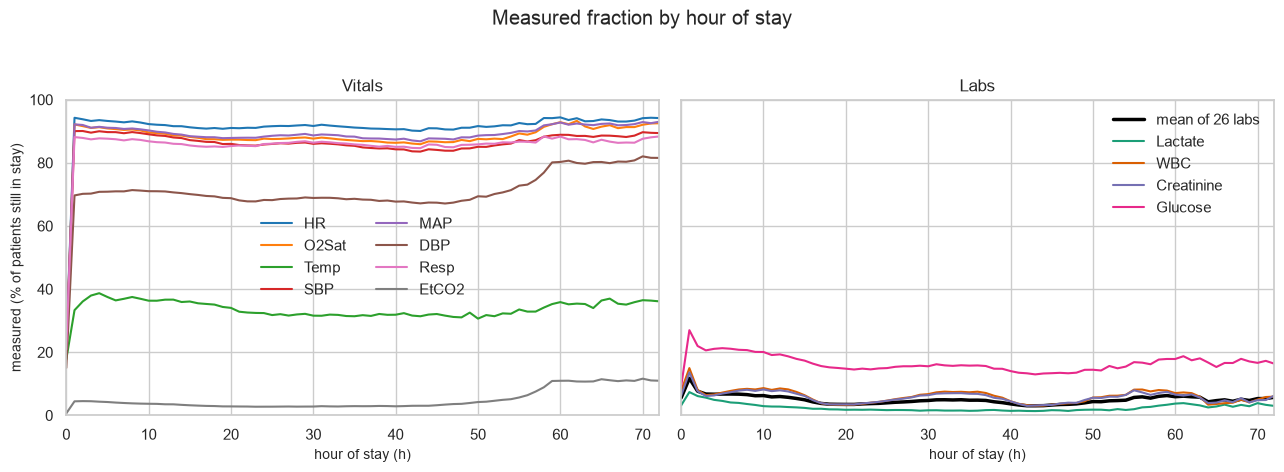

In [9]:
measured = df[FEATURES].notna()
early = df["hour"] <= 72
by_hour = measured.loc[early, VITALS + LABS].groupby(df.loc[early, "hour"]).mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for color, col in zip(sns.color_palette("tab10", len(VITALS)), VITALS):
    axes[0].plot(by_hour.index, by_hour[col], color=color, label=col)
axes[0].set(title="Vitals", xlabel="hour of stay (h)", ylabel="measured (% of patients still in stay)", xlim=(0, 72), ylim=(0, 100))
axes[0].legend(ncol=2)

axes[1].plot(by_hour.index, by_hour[LABS].mean(axis=1), color="black", lw=2.5, label="mean of 26 labs")
for color, col in zip(sns.color_palette("Dark2", 4), ["Lactate", "WBC", "Creatinine", "Glucose"]):
    axes[1].plot(by_hour.index, by_hour[col], color=color, label=col)
axes[1].set(title="Labs", xlabel="hour of stay (h)", xlim=(0, 72))
axes[1].legend()
fig.suptitle("Measured fraction by hour of stay")
save_fig("fig02_measured_by_hour.png", top=0.95)

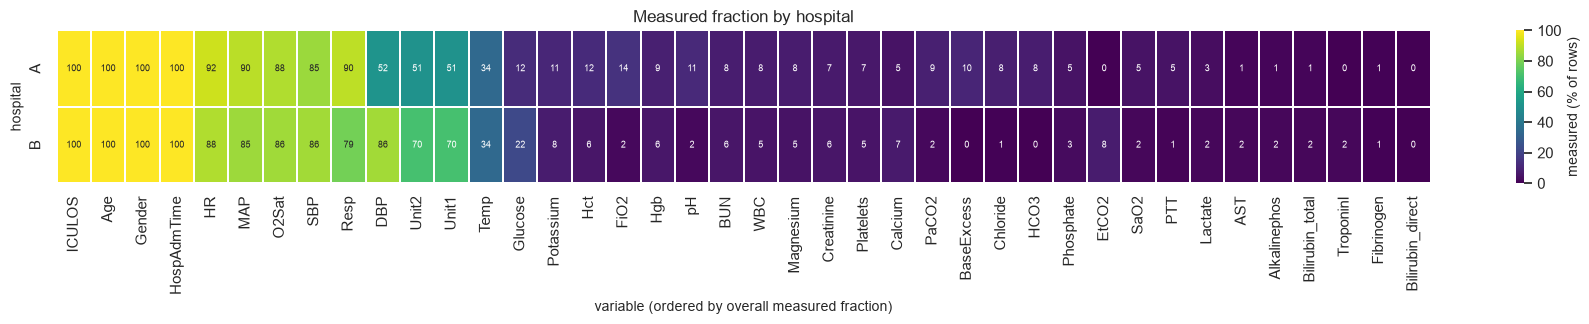

three largest differences in measured fraction between hospitals (percentage points)
       measured_pct_A  measured_pct_B  abs_diff_pct_points
DBP            51.870          86.060               34.180
Unit2          51.130          70.370               19.240
Unit1          51.130          70.370               19.240


In [10]:
frac_hosp = measured.groupby(df["hospital"]).mean() * 100
col_order = (measured.mean() * 100).sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(18, 3.4))
sns.heatmap(frac_hosp[col_order], annot=True, fmt=".0f", annot_kws={"size": 6.5}, cmap="viridis", vmin=0, vmax=100,
            linewidths=0.3, cbar_kws={"label": "measured (% of rows)"}, ax=ax)
ax.set_xlabel("variable (ordered by overall measured fraction)")
ax.set_ylabel("hospital")
ax.set_title("Measured fraction by hospital")
plt.xticks(rotation=90)
save_fig("fig02_measured_by_hospital.png")

hosp_tbl = frac_hosp.T
hosp_tbl.columns = [f"measured_pct_{h}" for h in hosp_tbl.columns]
hosp_tbl["abs_diff_pct_points"] = (hosp_tbl["measured_pct_A"] - hosp_tbl["measured_pct_B"]).abs()
save_table(hosp_tbl.loc[col_order].round(3), "measured_fraction_by_hospital.csv", index_label="column")

log("three largest differences in measured fraction between hospitals (percentage points)")
log(hosp_tbl.sort_values("abs_diff_pct_points", ascending=False).head(3).round(2).to_string())
del measured, by_hour

## Class balance

Patients and rows, overall and per hospital.

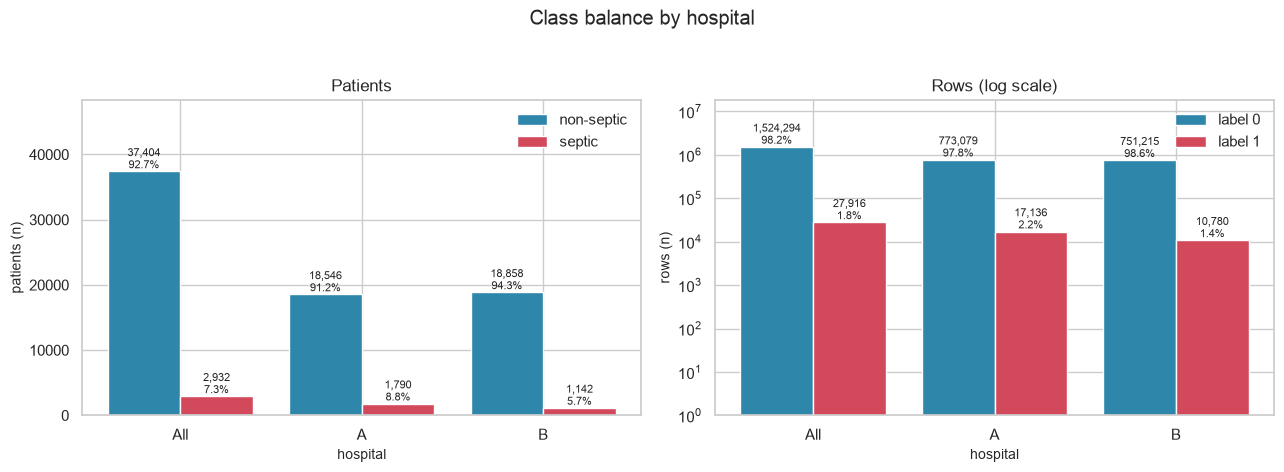

All: septic patients 2,932 of 40,336 (7.27%), label-1 rows 27,916 of 1,552,210 (1.80%)
A: septic patients 1,790 of 20,336 (8.80%), label-1 rows 17,136 of 790,215 (2.17%)
B: septic patients 1,142 of 20,000 (5.71%), label-1 rows 10,780 of 761,995 (1.41%)


In [11]:
def balance_table(pos, total):
    tbl = pd.DataFrame({"pos": pos, "total": total})
    tbl.loc["All"] = tbl.sum()
    tbl = tbl.loc[["All", "A", "B"]].copy()
    tbl["neg"] = tbl["total"] - tbl["pos"]
    tbl["pos_pct"] = tbl["pos"] / tbl["total"] * 100
    return tbl


def balance_panel(ax, tbl, names, title, ylabel, log_scale=False):
    x = np.arange(len(tbl))
    for shift, col, name, color in [(-0.2, "neg", names[0], COL_CONTROL), (0.2, "pos", names[1], COL_SEPTIC)]:
        bars = ax.bar(x + shift, tbl[col], width=0.4, color=color, label=name)
        pct = tbl[col] / tbl["total"] * 100
        ax.bar_label(bars, labels=[f"{n:,.0f}\n{p:.1f}%" for n, p in zip(tbl[col], pct)], fontsize=8)
    ax.set_xticks(x, list(tbl.index))
    ax.set(title=title, xlabel="hospital", ylabel=ylabel)
    top = tbl["total"].max()
    if log_scale:
        ax.set_yscale("log")
        ax.set_ylim(1, top * 12)
    else:
        ax.set_ylim(0, top * 1.2)
    ax.legend()


pat_bal = balance_table(patients.groupby("hospital")["ever_septic"].sum(), patients.groupby("hospital").size())
row_bal = balance_table(df.groupby("hospital")[TARGET].sum(), df.groupby("hospital").size())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
balance_panel(axes[0], pat_bal, ["non-septic", "septic"], "Patients", "patients (n)")
balance_panel(axes[1], row_bal, ["label 0", "label 1"], "Rows (log scale)", "rows (n)", log_scale=True)
fig.suptitle("Class balance by hospital")
save_fig("fig02_class_balance.png", top=0.95)

for scope in pat_bal.index:
    log(f"{scope}: septic patients {pat_bal.loc[scope, 'pos']:,.0f} of {pat_bal.loc[scope, 'total']:,.0f} "
        f"({pat_bal.loc[scope, 'pos_pct']:.2f}%), label-1 rows {row_bal.loc[scope, 'pos']:,.0f} of "
        f"{row_bal.loc[scope, 'total']:,.0f} ({row_bal.loc[scope, 'pos_pct']:.2f}%)")

## Stay length

Number of rows per patient, by outcome and by hospital.

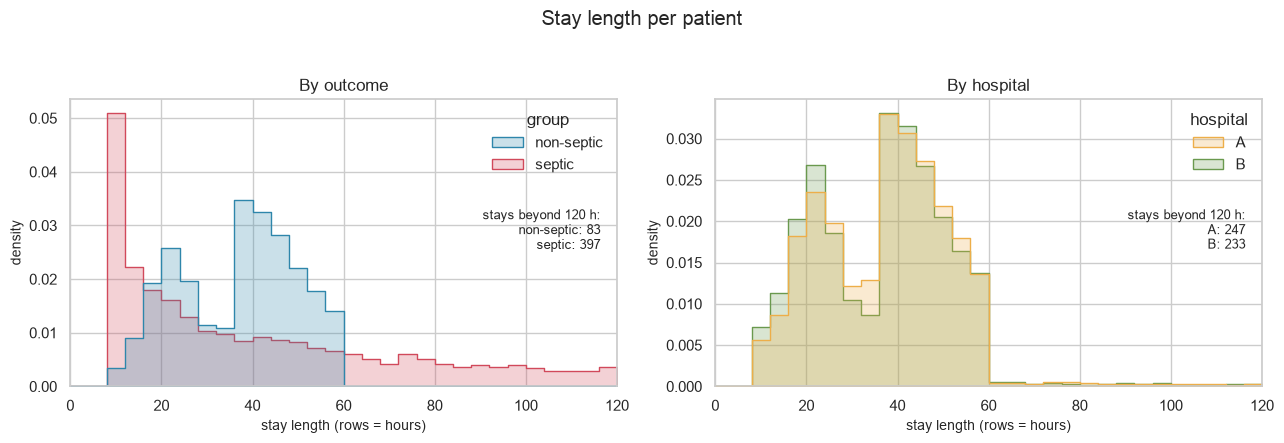

stay length (rows per patient) by outcome
            patients  median   mean  pct_under_24_rows
group                                                 
non-septic     37404  39.000 36.890             22.960
septic          2932  37.500 58.800             37.110
stay length by hospital
          patients  median   mean  pct_under_24_rows
hospital                                            
A            20336  39.000 38.860             22.120
B            20000  38.000 38.100             25.880
all patients: median 38.0, mean 38.48, under 24 rows 23.99%


In [12]:
LIM = 120
within = patients.loc[patients["n_rows"] <= LIM]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, key, palette, order in [(axes[0], "group", PAL_GROUP, ["non-septic", "septic"]), (axes[1], "hospital", PAL_HOSP, ["A", "B"])]:
    sns.histplot(data=within, x="n_rows", hue=key, hue_order=order, palette=palette, stat="density", common_norm=False,
                 binwidth=4, binrange=(0, LIM), element="step", ax=ax)
    beyond = patients.loc[patients["n_rows"] > LIM].groupby(key).size().reindex(order, fill_value=0)
    ax.text(0.97, 0.62, f"stays beyond {LIM} h:\n" + "\n".join(f"{k}: {v:,}" for k, v in beyond.items()),
            transform=ax.transAxes, ha="right", va="top", fontsize=9)
    ax.set_xlim(0, LIM)
    ax.set_xlabel("stay length (rows = hours)")
    ax.set_ylabel("density")
axes[0].set_title("By outcome")
axes[1].set_title("By hospital")
fig.suptitle("Stay length per patient")
save_fig("fig02_stay_length.png", top=0.95)


def stay_stats(key):
    short = patients["n_rows"].lt(24).groupby(patients[key]).mean() * 100
    grp = patients.groupby(key)["n_rows"]
    return pd.DataFrame({"patients": grp.size(), "median": grp.median(), "mean": grp.mean(), "pct_under_24_rows": short})


log("stay length (rows per patient) by outcome")
log(stay_stats("group").round(2).to_string())
log("stay length by hospital")
log(stay_stats("hospital").round(2).to_string())
log(f"all patients: median {patients['n_rows'].median():.1f}, mean {patients['n_rows'].mean():.2f}, "
    f"under 24 rows {patients['n_rows'].lt(24).mean() * 100:.2f}%")

## Label structure

When the label turns on and how long it stays on.

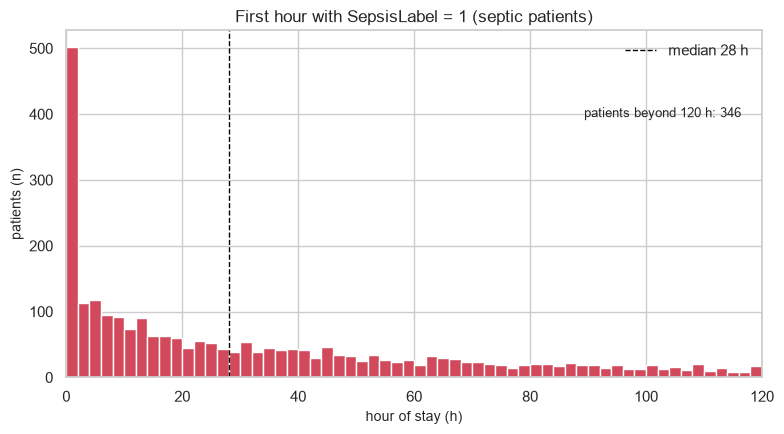

first_positive_hour (septic patients)
count   2932.000
mean      49.280
std       59.100
min        0.000
25%        5.750
50%       28.000
75%       71.000
max      330.000
labelled 1 in first row: 426 (14.53% of septic patients)
positive rows per septic patient
min 1, median 10.0, max 10, mean 9.52
share of rows of septic patients that are positive: 16.19%
[PASS] label never returns to 0 once it is 1 (0 drops)
[PASS] positive rows == n_rows - first_positive_hour for every septic patient


In [13]:
septic = patients.loc[patients["ever_septic"]]
onset = septic["first_positive_hour"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(onset[onset <= LIM], bins=np.arange(0, LIM + 2, 2), color=COL_SEPTIC)
ax.axvline(onset.median(), color="black", ls="--", lw=1, label=f"median {onset.median():.0f} h")
ax.text(0.97, 0.75, f"patients beyond {LIM} h: {int((onset > LIM).sum()):,}", transform=ax.transAxes, ha="right", fontsize=9)
ax.set(title="First hour with SepsisLabel = 1 (septic patients)", xlabel="hour of stay (h)", ylabel="patients (n)", xlim=(0, LIM))
ax.legend()
save_fig("fig02_onset_hour.png")

log("first_positive_hour (septic patients)")
log(onset.describe().round(2).to_string())
log(f"labelled 1 in first row: {int((onset == 0).sum()):,} ({(onset == 0).mean() * 100:.2f}% of septic patients)")
log("positive rows per septic patient")
log(f"min {septic['n_positive_rows'].min()}, median {septic['n_positive_rows'].median():.1f}, "
    f"max {septic['n_positive_rows'].max()}, mean {septic['n_positive_rows'].mean():.2f}")
log(f"share of rows of septic patients that are positive: {septic['n_positive_rows'].sum() / septic['n_rows'].sum() * 100:.2f}%")

label_drops = int((df.groupby("pid")[TARGET].diff() < 0).sum())
check("label never returns to 0 once it is 1", label_drops == 0, f"{label_drops:,} drops")
stays_on = (septic["n_positive_rows"] == septic["n_rows"] - septic["first_positive_hour"]).all()
check("positive rows == n_rows - first_positive_hour for every septic patient", bool(stays_on))

## Trajectories before onset

Septic patients are aligned on their first label-1 hour. Non-septic patients get a seeded pseudo-onset so both groups share one relative time axis.

In [14]:
R_MIN, R_MAX = -24, 6
TRAJ_VARS = ["HR", "Resp", "Temp", "MAP", "Lactate"]
UNITS = {"HR": "HR (beats/min)", "Resp": "Resp (breaths/min)", "Temp": "Temp (deg C)", "MAP": "MAP (mm Hg)", "Lactate": "Lactate (mg/dL)"}

pool = np.sort(patients.loc[patients["ever_septic"], "first_positive_hour"].to_numpy().astype(np.int64))
is_ctrl = ~patients["ever_septic"].to_numpy()
n_rows_arr = patients["n_rows"].to_numpy().astype(np.int64)

t0 = patients["first_positive_hour"].to_numpy(dtype="float64")
n_valid = np.searchsorted(pool, n_rows_arr[is_ctrl], side="left")
draw_rng = np.random.default_rng(SEED)
pick = np.minimum((draw_rng.random(is_ctrl.sum()) * n_valid).astype(np.int64), np.maximum(n_valid - 1, 0))
t0[is_ctrl] = np.where(n_valid > 0, pool[pick], n_rows_arr[is_ctrl] - 1)
patients["t0"] = t0.astype(np.int64)

log(f"non-septic patients with no qualifying onset hour (last hour used): {int((n_valid == 0).sum()):,}")
log(f"median t0, septic {patients.loc[patients['ever_septic'], 't0'].median():.1f}, "
    f"non-septic {patients.loc[~patients['ever_septic'], 't0'].median():.1f}")

pid_arr = df["pid"].to_numpy()
rel = df["hour"].to_numpy().astype(np.int32) - patients["t0"].to_numpy()[pid_arr]
in_win = (rel >= R_MIN) & (rel <= R_MAX)

win_cols = list(dict.fromkeys(["HR", "Resp", "Temp", "MAP"] + LABS))
win = df.loc[in_win, win_cols].reset_index(drop=True)
win["r"] = rel[in_win]
win["septic"] = patients["ever_septic"].to_numpy()[pid_arr][in_win]
log(f"rows in the window r = {R_MIN}..{R_MAX}: {len(win):,} (septic {int(win['septic'].sum()):,})")

non-septic patients with no qualifying onset hour (last hour used): 0
median t0, septic 28.0, non-septic 7.0
rows in the window r = -24..6: 662,605 (septic 67,402)


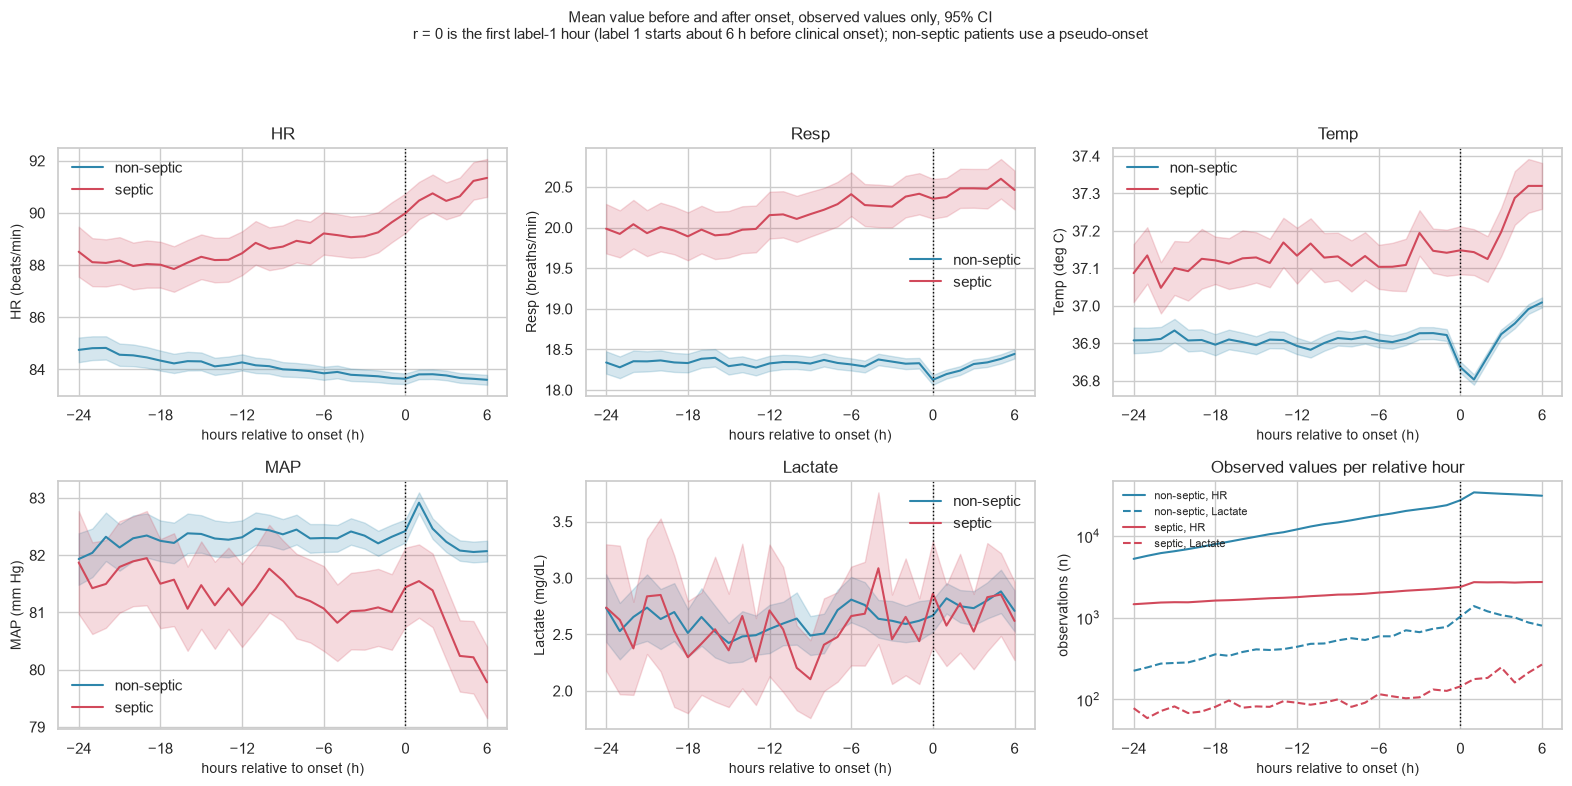

septic minus non-septic difference in mean (observed values only)
HR       r=-12: diff +4.182  (septic n=1,782, non-septic n=12,015)
HR       r= -6: diff +5.360  (septic n=2,025, non-septic n=17,796)
HR       r= -1: diff +5.969  (septic n=2,297, non-septic n=23,752)
Resp     r=-12: diff +1.826  (septic n=1,662, non-septic n=11,276)
Resp     r= -6: diff +2.096  (septic n=1,904, non-septic n=16,743)
Resp     r= -1: diff +2.087  (septic n=2,146, non-septic n=22,272)
Temp     r=-12: diff +0.241  (septic n=584, non-septic n=4,788)
Temp     r= -6: diff +0.197  (septic n=796, non-septic n=6,978)
Temp     r= -1: diff +0.220  (septic n=854, non-septic n=9,188)
MAP      r=-12: diff -1.191  (septic n=1,751, non-septic n=11,718)
MAP      r= -6: diff -1.231  (septic n=1,993, non-septic n=17,331)
MAP      r= -1: diff -1.314  (septic n=2,259, non-septic n=23,128)
Lactate  r=-12: diff +0.164  (septic n=91, non-septic n=440)
Lactate  r= -6: diff -0.146  (septic n=116, non-septic n=591)
Lactate  r= -1: 

In [15]:
def pre_onset_stats(var):
    s = win.groupby(["septic", "r"])[var].agg(["mean", "std", "count"])
    s["se"] = s["std"] / np.sqrt(s["count"])
    s["lo"] = s["mean"] - 1.96 * s["se"]
    s["hi"] = s["mean"] + 1.96 * s["se"]
    return s


traj = {v: pre_onset_stats(v) for v in TRAJ_VARS}
GROUPS = [(False, "non-septic", COL_CONTROL), (True, "septic", COL_SEPTIC)]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, var in zip(axes.ravel(), TRAJ_VARS):
    for flag, name, color in GROUPS:
        s = traj[var].xs(flag, level="septic")
        ax.plot(s.index, s["mean"], color=color, label=name)
        ax.fill_between(s.index, s["lo"], s["hi"], color=color, alpha=0.2)
    ax.axvline(0, color="black", ls=":", lw=1)
    ax.set(title=var, xlabel="hours relative to onset (h)", ylabel=UNITS[var], xticks=range(R_MIN, R_MAX + 1, 6))
    ax.legend()

ax = axes[1, 2]
for flag, name, color in GROUPS:
    for var, style in [("HR", "-"), ("Lactate", "--")]:
        c = traj[var].xs(flag, level="septic")["count"]
        ax.plot(c.index, c, color=color, ls=style, label=f"{name}, {var}")
ax.axvline(0, color="black", ls=":", lw=1)
ax.set_yscale("log")
ax.set(title="Observed values per relative hour", xlabel="hours relative to onset (h)", ylabel="observations (n)", xticks=range(R_MIN, R_MAX + 1, 6))
ax.legend(fontsize=8)
fig.suptitle("Mean value before and after onset, observed values only, 95% CI\n"
             "r = 0 is the first label-1 hour (label 1 starts about 6 h before clinical onset); non-septic patients use a pseudo-onset", fontsize=11)
save_fig("fig02_pre_onset_trajectories.png", top=0.92)

traj_long = pd.concat(traj, names=["variable"]).reset_index()
save_table(traj_long.round(4), "pre_onset_trajectory_stats.csv", index=False)

log("septic minus non-septic difference in mean (observed values only)")
for var in TRAJ_VARS:
    for r in (-12, -6, -1):
        m = traj[var]["mean"]
        n = traj[var]["count"]
        diff = m.get((True, r), np.nan) - m.get((False, r), np.nan)
        log(f"{var:8s} r={r:>3}: diff {diff:+.3f}  (septic n={int(n.get((True, r), 0)):,}, non-septic n={int(n.get((False, r), 0)):,})")

## Measurement frequency before onset

Same alignment, but counting whether a value was measured at all.

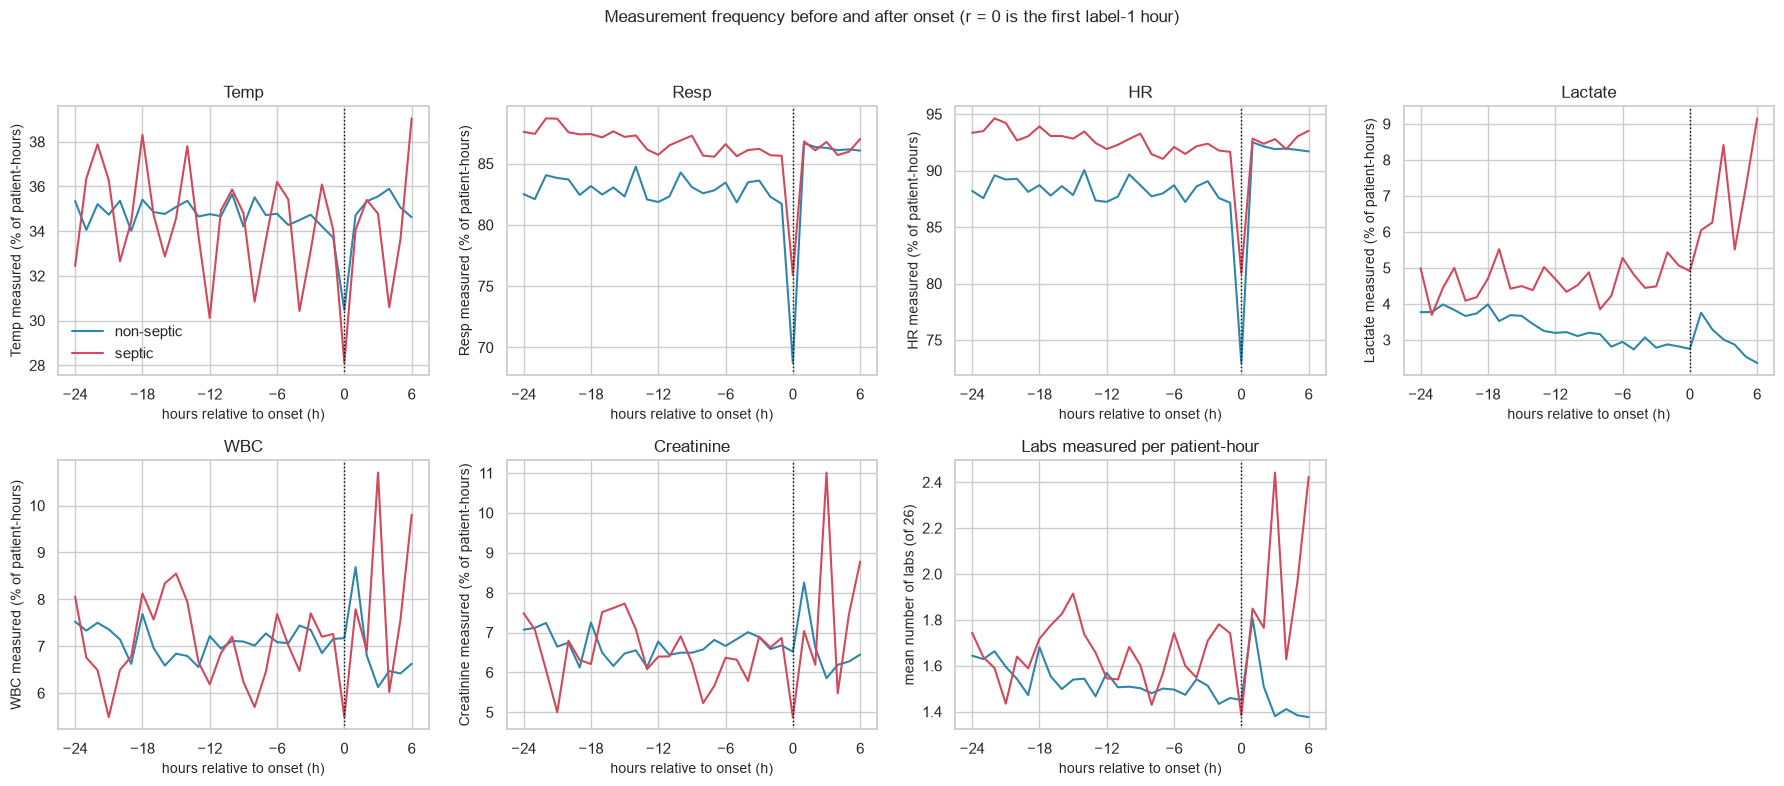

measurement rate at r = -6, septic versus non-septic
Temp                 septic 0.362, non-septic 0.348, ratio 1.04
Resp                 septic 0.866, non-septic 0.835, ratio 1.04
HR                   septic 0.921, non-septic 0.887, ratio 1.04
Lactate              septic 0.053, non-septic 0.029, ratio 1.79
WBC                  septic 0.077, non-septic 0.071, ratio 1.08
Creatinine           septic 0.064, non-septic 0.067, ratio 0.96
mean_labs_per_hour   septic 1.742, non-septic 1.496, ratio 1.16


In [16]:
FREQ_VARS = ["Temp", "Resp", "HR", "Lactate", "WBC", "Creatinine"]
win["n_labs"] = win[LABS].notna().sum(axis=1)

keys = [win["septic"], win["r"]]
freq = win[FREQ_VARS].notna().groupby(keys).mean() * 100
labs_per_hour = win["n_labs"].groupby(keys).mean()

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
panels = [(v, freq[v], f"{v} measured (% of patient-hours)") for v in FREQ_VARS]
panels.append(("Labs measured per patient-hour", labs_per_hour, "mean number of labs (of 26)"))
for ax, (title, series, ylabel) in zip(axes.ravel(), panels):
    for flag, name, color in GROUPS:
        s = series.xs(flag, level="septic")
        ax.plot(s.index, s.values, color=color, label=name)
    ax.axvline(0, color="black", ls=":", lw=1)
    ax.set(title=title, xlabel="hours relative to onset (h)", ylabel=ylabel, xticks=range(R_MIN, R_MAX + 1, 6))
axes[0, 0].legend()
axes[1, 3].axis("off")
fig.suptitle("Measurement frequency before and after onset (r = 0 is the first label-1 hour)", fontsize=12)
save_fig("fig02_measurement_frequency_pre_onset.png", top=0.95)

log("measurement rate at r = -6, septic versus non-septic")
rates = pd.concat([freq / 100, labs_per_hour.rename("mean_labs_per_hour")], axis=1)
for col in rates.columns:
    s_rate, c_rate = rates[col].get((True, -6), np.nan), rates[col].get((False, -6), np.nan)
    log(f"{col:20s} septic {s_rate:.3f}, non-septic {c_rate:.3f}, ratio {s_rate / c_rate:.2f}")

## Static features versus sepsis

Septic rate per patient, using the first row of each stay.

HospAdmTime quartile edges (first row): -5366.86, -43.68, -6.05, -0.04, 23.99


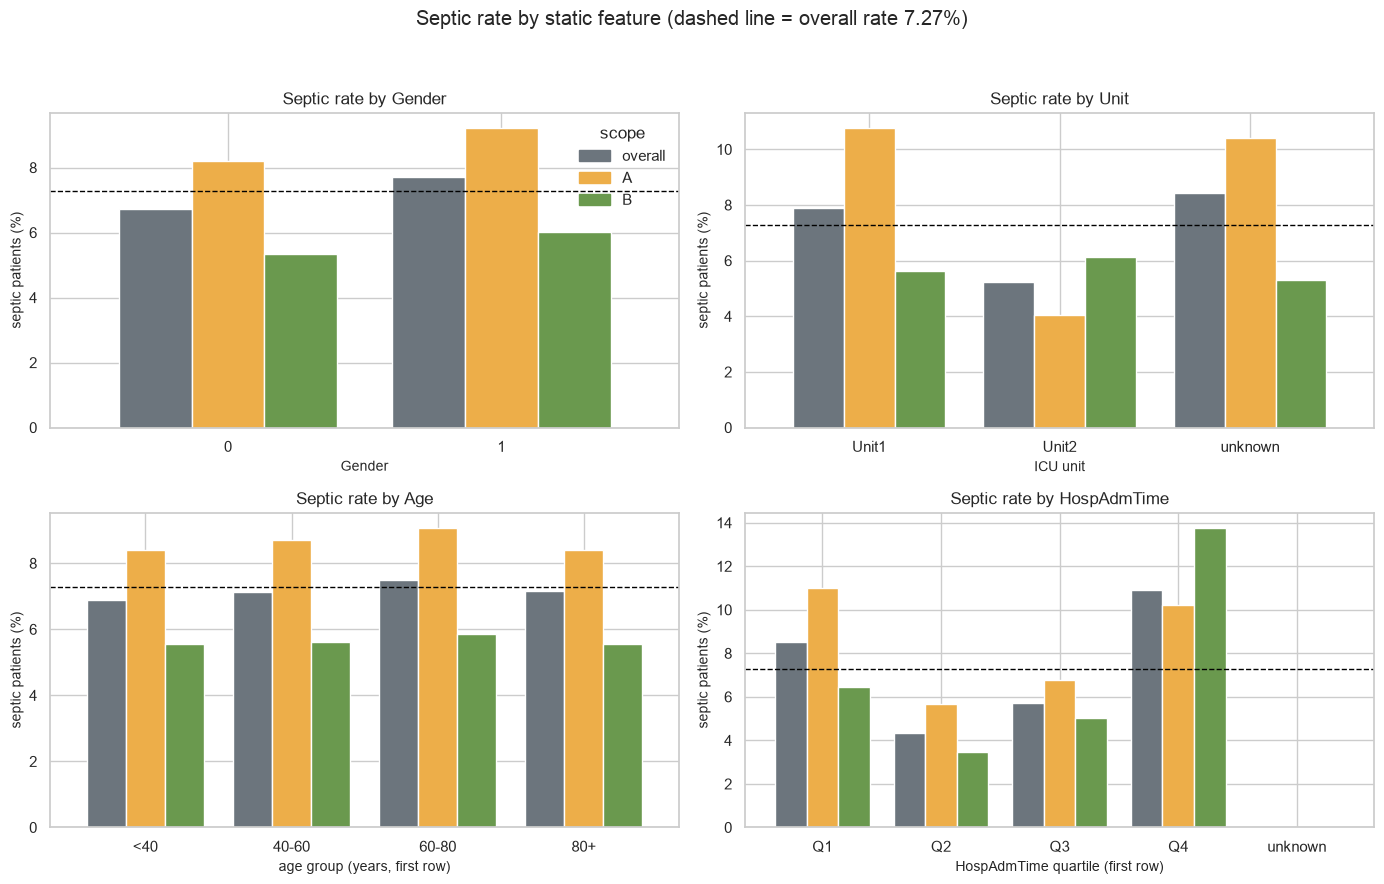

groups with septic rate more than 3 percentage points from the overall rate (7.27%)
   variable   scope   group  n_patients  n_septic  septic_rate_pct  diff_pct_points
       Unit       A   Unit1        5344       576           10.780            3.510
       Unit       A   Unit2        5470       222            4.060           -3.210
       Unit       A unknown        9522       992           10.420            3.150
HospAdmTime overall      Q4        9347      1018           10.890            3.620
HospAdmTime overall unknown           1         0            0.000           -7.270
HospAdmTime       A      Q1        4594       506           11.010            3.750
HospAdmTime       A unknown           1         0            0.000           -7.270
HospAdmTime       B      Q2        6210       215            3.460           -3.810
HospAdmTime       B      Q4        1771       244           13.780            6.510


In [17]:
first = df.loc[df["hour"] == 0, ["pid"] + STATIC].set_index("pid")
pt = patients[["hospital", "ever_septic"]].join(first)


def code_labels(s):
    return np.where(s.isna(), "unknown", s.fillna(-1).astype(int).astype(str))


pt["gender_grp"] = code_labels(pt["Gender"])
pt["unit_grp"] = np.select([pt["Unit1"] == 1, pt["Unit2"] == 1, pt["Unit1"].isna() & pt["Unit2"].isna()],
                           ["Unit1", "Unit2", "unknown"], default="other")
age_bins = pd.cut(pt["Age"], [-np.inf, 40, 60, 80, np.inf], right=False, labels=["<40", "40-60", "60-80", "80+"])
pt["age_grp"] = np.where(pt["Age"].isna(), "unknown", age_bins.astype(str))
adm_q, adm_edges = pd.qcut(pt["HospAdmTime"], 4, labels=False, retbins=True, duplicates="drop")
pt["adm_grp"] = np.where(adm_q.isna(), "unknown", "Q" + (adm_q.fillna(-1).astype(int) + 1).astype(str))
log("HospAdmTime quartile edges (first row): " + ", ".join(f"{e:.2f}" for e in adm_edges))

SCOPES = ["overall", "A", "B"]
SCOPE_COL = [COL_ALL, COL_A, COL_B]
specs = [
    ("Gender", "gender_grp", ["0", "1", "unknown"], "Gender"),
    ("Unit", "unit_grp", ["Unit1", "Unit2", "unknown", "other"], "ICU unit"),
    ("Age", "age_grp", ["<40", "40-60", "60-80", "80+", "unknown"], "age group (years, first row)"),
    ("HospAdmTime", "adm_grp", ["Q1", "Q2", "Q3", "Q4", "unknown"], "HospAdmTime quartile (first row)"),
]


def rate_table(variable, col, order):
    parts = []
    for scope in SCOPES:
        sub = pt if scope == "overall" else pt.loc[pt["hospital"] == scope]
        g = sub.groupby(col)["ever_septic"].agg(n_patients="size", n_septic="sum").reindex(order).dropna()
        g = g.astype({"n_patients": "int64", "n_septic": "int64"}).rename_axis("group").reset_index()
        g.insert(0, "scope", scope)
        g.insert(0, "variable", variable)
        parts.append(g)
    out = pd.concat(parts, ignore_index=True)
    out["septic_rate_pct"] = out["n_septic"] / out["n_patients"] * 100
    return out


rates_static = pd.concat([rate_table(v, c, o) for v, c, o, _ in specs], ignore_index=True)
save_table(rates_static.round(3), "septic_rate_by_static.csv", index=False)

overall_rate = patients["ever_septic"].mean() * 100
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (variable, _, order, xlabel) in zip(axes.ravel(), specs):
    sub = rates_static.loc[rates_static["variable"] == variable]
    wide = sub.pivot(index="group", columns="scope", values="septic_rate_pct").reindex(
        [g for g in order if g in set(sub["group"])])[SCOPES]
    wide.plot.bar(ax=ax, color=SCOPE_COL, width=0.8, rot=0, legend=False)
    ax.axhline(overall_rate, color="black", ls="--", lw=1)
    ax.set(title=f"Septic rate by {variable}", xlabel=xlabel, ylabel="septic patients (%)")
from matplotlib.patches import Patch
axes[0, 0].legend(handles=[Patch(color=c, label=s) for s, c in zip(SCOPES, SCOPE_COL)], title="scope")
fig.suptitle(f"Septic rate by static feature (dashed line = overall rate {overall_rate:.2f}%)")
save_fig("fig02_static_vs_sepsis.png", top=0.95)

log(f"groups with septic rate more than 3 percentage points from the overall rate ({overall_rate:.2f}%)")
flagged = rates_static.loc[(rates_static["septic_rate_pct"] - overall_rate).abs() > 3].copy()
flagged["diff_pct_points"] = flagged["septic_rate_pct"] - overall_rate
if flagged.empty:
    log("none")
else:
    log(flagged.round(2).to_string(index=False))

## Correlation

Spearman correlation on a seeded sample of 200,000 rows, pairwise complete observations.

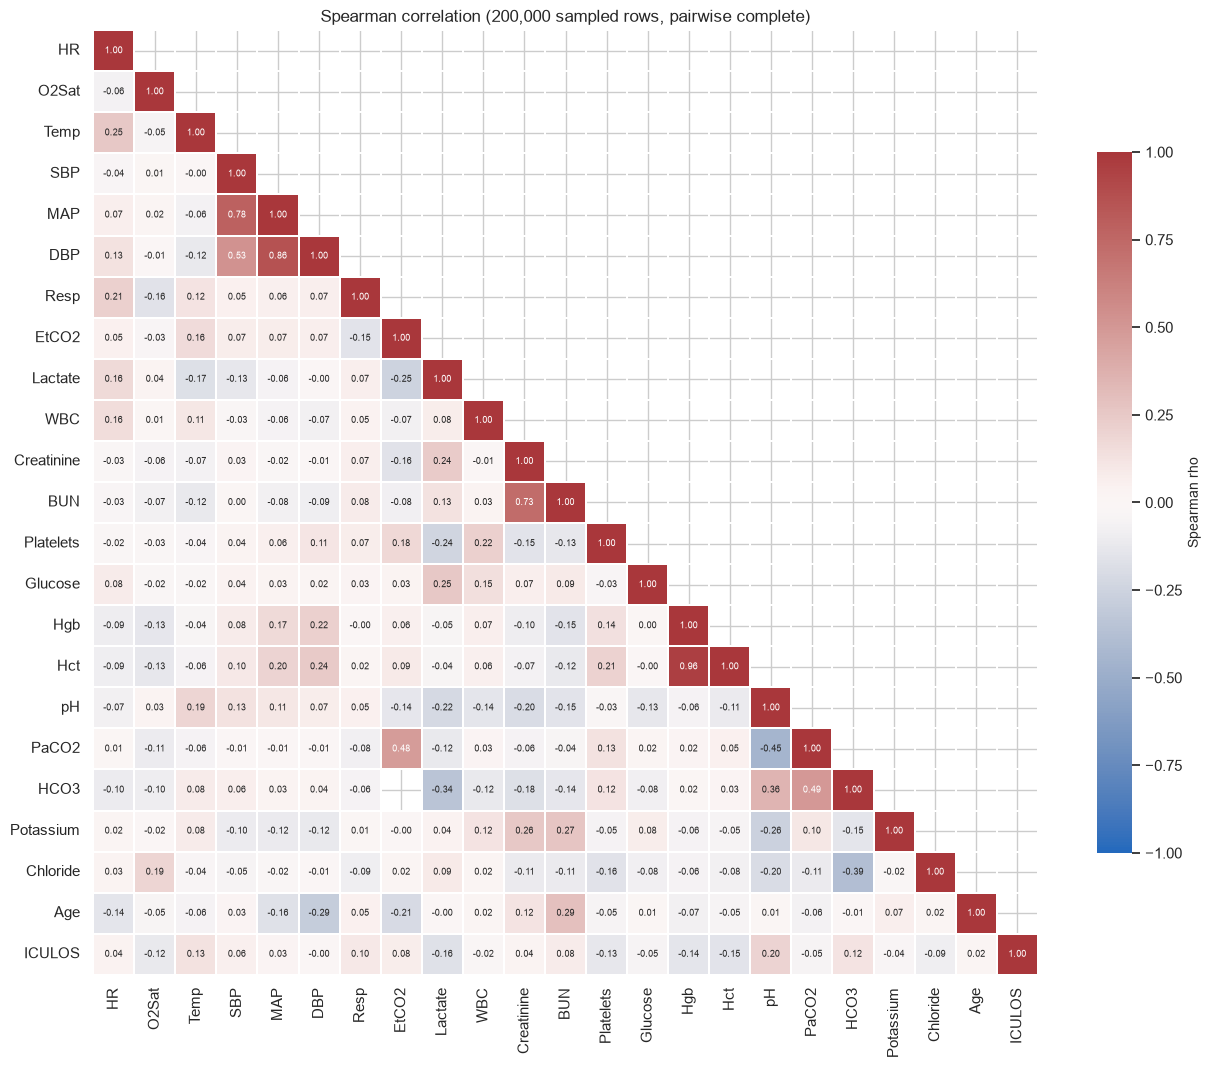

smallest number of complete pairs in the matrix: 9
8 most correlated pairs (absolute Spearman rho)
      var1  var2    rho  n_pairs
       Hgb   Hct  0.955    14451
       MAP   DBP  0.865   136046
       SBP   MAP  0.782   168916
Creatinine   BUN  0.728    12103
       SBP   DBP  0.528   137257
     PaCO2  HCO3  0.494     2238
     EtCO2 PaCO2  0.484      676
        pH PaCO2 -0.446    10980


In [18]:
CORR_VARS = VITALS + ["Lactate", "WBC", "Creatinine", "BUN", "Platelets", "Glucose", "Hgb", "Hct", "pH", "PaCO2",
                      "HCO3", "Potassium", "Chloride", "Age", "ICULOS"]
sample_rows = np.sort(np.random.default_rng(SEED).choice(len(df), size=min(200_000, len(df)), replace=False))
sample = df.iloc[sample_rows].loc[:, CORR_VARS]

corr = sample.corr(method="spearman", min_periods=30)
observed = sample.notna().astype("int32")
pair_n = observed.T.dot(observed)

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, mask=np.triu(np.ones(corr.shape, dtype=bool), k=1), cmap="vlag", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 6.5}, square=True, linewidths=0.3,
            cbar_kws={"label": "Spearman rho", "shrink": 0.7}, ax=ax)
ax.set_title("Spearman correlation (200,000 sampled rows, pairwise complete)")
save_fig("fig02_correlation.png")
save_table(corr.round(4), "correlation_spearman.csv", index_label="variable")

i, j = np.triu_indices(len(corr), k=1)
pairs = pd.DataFrame({"var1": corr.columns[i], "var2": corr.columns[j], "rho": corr.to_numpy()[i, j], "n_pairs": pair_n.to_numpy()[i, j]})
pairs = pairs.dropna(subset=["rho"]).sort_values("rho", key=np.abs, ascending=False)
log(f"smallest number of complete pairs in the matrix: {int(pair_n.to_numpy()[i, j].min()):,}")
log("8 most correlated pairs (absolute Spearman rho)")
log(pairs.head(8).round(3).to_string(index=False))

## Output files

In [19]:
summary_path = TAB.parent / "step02_summary.txt"

log("")
log("saved files")
for path in SAVED:
    status = f"{path.stat().st_size / 1e6:.2f} MB" if path.exists() else "MISSING"
    log(f"  {path.relative_to(ROOT)}  {status}")
log(f"  {summary_path.relative_to(ROOT)}  (this file)")

summary_path.write_text("\n".join(SUMMARY) + "\n")
print()
print(summary_path)


saved files
  data/processed/patient_table.csv  0.90 MB
  results/figures/fig02_missing_by_column.png  0.10 MB
  results/figures/fig02_measured_by_hour.png  0.15 MB
  results/figures/fig02_measured_by_hospital.png  0.11 MB
  results/tables/measured_fraction_by_hospital.csv  0.00 MB
  results/figures/fig02_class_balance.png  0.07 MB
  results/figures/fig02_stay_length.png  0.08 MB
  results/figures/fig02_onset_hour.png  0.04 MB
  results/figures/fig02_pre_onset_trajectories.png  0.44 MB
  results/tables/pre_onset_trajectory_stats.csv  0.02 MB
  results/figures/fig02_measurement_frequency_pre_onset.png  0.41 MB
  results/tables/septic_rate_by_static.csv  0.00 MB
  results/figures/fig02_static_vs_sepsis.png  0.12 MB
  results/figures/fig02_correlation.png  0.25 MB
  results/tables/correlation_spearman.csv  0.00 MB
  results/step02_summary.txt  (this file)

/Users/harnoorkaur/Downloads/Sepsis_ml/results/step02_summary.txt
